# 1. Librerías y Banco de Funciones de Prueba 

In [8]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

v_pi = math.pi

# ==============================================================================
# BANCO DE FUNCIONES DE PRUEBA (ANEXO TAREA 4)
# ==============================================================================

def F1_xy(x, y):
    # Minimizar en {[-10, 10], [-10, 10]} | Minimo global: 0.0 en (0, 0)
    return x**2 + 2*(y**2) - 0.3*math.cos(3*v_pi*x) - 0.4*math.cos(4*v_pi*y) + 0.7

def F2_xy(x, y):
    # Maximizar en {[-100, 100], [-100, 100]} | Maximo global: 1.0 en (0, 0)
    r2 = x**2 + y**2
    numerador = (math.sin(math.sqrt(r2))**2) - 0.5
    denominador = (1.0 + 0.001 * r2)**2
    return 0.5 - (numerador / denominador)

def F3_xy(x, y):
    # Maximizar en {[-3, 12.1], [4.1, 5.8]} | Maximo global aprox: ~38.85
    return 21.5 + x * math.sin(4*v_pi*x) + y * math.sin(20*v_pi*y)

def F4_xy(x, y):
    # Minimizar en {[-100, 100], [-100, 100]} | Minimo global: 0.0 en (0, 0)
    r2 = x**2 + y**2
    return (r2**0.25) * ((math.sin(50 * (r2**0.1))**2) + 1.0)

def F5_xyz(x, y, z):
    # Minimizar en {[-100, 100], [-100, 100], [-100, 100]} | Minimo global: 0.0 en (0, 0, 0)
    termino1 = ((x**2 + y**2)**0.25) * (1.0 + (math.sin(50 * (x**2 + y**2)**0.1))**2)
    termino2 = ((y**2 + z**2)**0.25) * (1.0 + (math.sin(50 * (y**2 + z**2)**0.1))**2)
    termino3 = ((x**2 + z**2)**0.25) * (1.0 + (math.sin(50 * (x**2 + z**2)**0.1))**2)
    return termino1 + termino2 + termino3


# Diccionario maestro de configuracion de las 5 funciones
CATALOGO_FUNCIONES = {
    "F1": {"tipo": "MIN", "rangos": [(-10.0, 10.0), (-10.0, 10.0)], "func": F1_xy},
    "F2": {"tipo": "MAX", "rangos": [(-100.0, 100.0), (-100.0, 100.0)], "func": F2_xy},
    "F3": {"tipo": "MAX", "rangos": [(-3.0, 12.1), (4.1, 5.8)], "func": F3_xy},
    "F4": {"tipo": "MIN", "rangos": [(-100.0, 100.0), (-100.0, 100.0)], "func": F4_xy},
    "F5": {"tipo": "MIN", "rangos": [(-100.0, 100.0), (-100.0, 100.0), (-100.0, 100.0)], "func": F5_xyz}
}

# 2. Codificación, Evaluación y Operadores Base (Tareas 2 y 3)

In [9]:
# ==============================================================================
# CALCULO DE BITS, DECODIFICACION Y EVALUACION (REUTILIZADO DE TAREA 2)
# ==============================================================================

def calcular_estructura_bits(nombre_func, precision_digitos=2):
    """Calcula los bits necesarios por variable garantizando precision >= 10^-p"""
    factor_10 = 10 ** precision_digitos
    rangos = CATALOGO_FUNCIONES[nombre_func]["rangos"]
    bits_por_variable = []

    for lim_inf, lim_sup in rangos:
        longitud = lim_sup - lim_inf
        n_bits = math.ceil(math.log2(longitud * factor_10 + 1))
        bits_por_variable.append(n_bits)

    return bits_por_variable

def decodificar_variable(cadena_bits, limite_inf, limite_sup):
    cadena_binaria = "".join(map(str, cadena_bits))
    decimal = int(cadena_binaria, 2)
    m = len(cadena_bits)
    max_decimal = (2**m) - 1
    return limite_inf + decimal * ((limite_sup - limite_inf) / max_decimal)

def decodificar_individuo(cromosoma, nombre_func, bits_vars):
    rangos = CATALOGO_FUNCIONES[nombre_func]["rangos"]
    valores_reales = []
    inicio = 0
    for idx, n_bits in enumerate(bits_vars):
        gen = cromosoma[inicio : inicio + n_bits]
        inicio += n_bits
        val = decodificar_variable(gen, rangos[idx][0], rangos[idx][1])
        valores_reales.append(val)
    return valores_reales

def evaluar_individuo(cromosoma, nombre_func, bits_vars):
    """
    Retorna:
    - adaptacion: Fitness natural del individuo (mayor siempre es mejor)
    - valor_f: Valor real de la funcion F(x,y,[z])
    - coords: Lista con los valores reales [x, y, (z)]
    """
    info = CATALOGO_FUNCIONES[nombre_func]
    coords = decodificar_individuo(cromosoma, nombre_func, bits_vars)
    valor_f = info["func"](*coords)

    if info["tipo"] == "MAX":
        adaptacion = valor_f if valor_f > 0 else 1e-6
    else: # MIN
        # Transformacion estandar para minimizacion (Tarea 2)
        adaptacion = 1.0 / (1.0 + valor_f) if valor_f >= 0 else 1.0 / (1.0 + abs(valor_f))

    return adaptacion, valor_f, coords


# ==============================================================================
# OPERADORES DE SELECCION (TAREA 3), CRUCE Y MUTACION (TAREA 2)
# ==============================================================================

def seleccion_ruleta_individuo(poblacion, aptitudes):
    suma_total = sum(aptitudes)
    if suma_total <= 0:
        return random.choice(poblacion)[:]
    r = random.uniform(0, suma_total)
    acumulado = 0.0
    for ind, apt in zip(poblacion, aptitudes):
        acumulado += apt
        if acumulado >= r:
            return ind[:]
    return poblacion[-1][:]

def seleccion_universal_estocastica_n(poblacion, aptitudes, n_seleccionar):
    """SUS de la Tarea 3 adaptada para elegir exactamente 'n_seleccionar' padres"""
    suma_total = sum(aptitudes)
    if suma_total <= 0:
        return [random.choice(poblacion)[:] for _ in range(n_seleccionar)]
    distancia = suma_total / n_seleccionar
    inicio = random.uniform(0, distancia)
    punteros = [inicio + i * distancia for i in range(n_seleccionar)]

    padres = []
    acumulado = aptitudes[0]
    idx = 0
    n_pob = len(poblacion)
    for p in punteros:
        while acumulado < p and idx < n_pob - 1:
            idx += 1
            acumulado += aptitudes[idx]
        padres.append(poblacion[idx][:])
    random.shuffle(padres)
    return padres

def cruce_un_punto(padre1, padre2, prob_cruce):
    if random.random() < prob_cruce:
        punto = random.randint(1, len(padre1) - 1)
        return padre1[:punto] + padre2[punto:], padre2[:punto] + padre1[punto:]
    return padre1[:], padre2[:]

def mutacion(cromosoma, prob_mutacion):
    for i in range(len(cromosoma)):
        if random.random() < prob_mutacion:
            cromosoma[i] = 1 - cromosoma[i]
    return cromosoma

# 3. Nuevos Módulos de la Tarea 4 (Renormalización, Elitismo, Gap y Sin Duplicados)

In [10]:
# ==============================================================================
# RENORMALIZACION LINEAL (AGM2 en adelante)
# ==============================================================================
def aplicar_renormalizacion_lineal(poblacion_ordenada, tope=100.0, paso=1.0):
    """
    Recibe la poblacion YA ORDENADA de mejor a peor adaptacion.
    Asigna aptitud lineal: Tope - i * Paso (acotada a un minimo positivo).
    """
    n = len(poblacion_ordenada)
    aptitudes_renorm = []
    for i in range(n):
        val = tope - (i * paso)
        if val <= 0:
            val = 1e-4
        aptitudes_renorm.append(val)
    return aptitudes_renorm


# ==============================================================================
# MOTOR EVOLUTIVO GENERAL PARAMETRIZADO (SOPORTA AGS1, AGM2, AGM3, AGM4, AGM5)
# ==============================================================================
def ejecutar_ag_general(
    nombre_func,
    n_pob=100,
    max_evaluaciones=5000,
    pc=0.9,
    pm=0.01,
    precision=2,
    usar_renormalizacion=False,
    tope=100.0,
    paso=1.0,
    usar_elitismo=False,
    usar_sustitucion_parcial=False,
    gap=0.10,
    evitar_duplicados=False,
    metodo_seleccion="RULETA"
):
    bits_vars = calcular_estructura_bits(nombre_func, precision)
    long_cromosoma = sum(bits_vars)
    tipo_opt = CATALOGO_FUNCIONES[nombre_func]["tipo"]

    # 1. Inicializacion de la poblacion (Con control de duplicados si AGM5 esta activo)
    poblacion = []
    registro_unicos = set()

    while len(poblacion) < n_pob:
        crom = [random.randint(0, 1) for _ in range(long_cromosoma)]
        t_crom = tuple(crom)
        if evitar_duplicados:
            if t_crom not in registro_unicos:
                registro_unicos.add(t_crom)
                poblacion.append(crom)
        else:
            poblacion.append(crom)

    # Evaluacion de la poblacion inicial (No cuenta dentro de las 'max_evaluaciones' nuevas,
    # tal como indica la guia: "5000 nuevos individuos sin contar los iniciales")
    datos_pob = []
    for crom in poblacion:
        adap, val_f, coords = evaluar_individuo(crom, nombre_func, bits_vars)
        datos_pob.append({"crom": crom, "adap": adap, "val_f": val_f, "coords": coords})

    # Determinar cuantos individuos nuevos se evaluan por generacion
    if usar_sustitucion_parcial:
        n_reemplazo = max(1, int(round(n_pob * gap)))
    else:
        n_reemplazo = n_pob

    evaluaciones_actuales = 0
    eje_evaluaciones = [0]

    # Estadisticas iniciales
    adaptaciones_actuales = [d["adap"] for d in datos_pob]
    historial_max_adap = [max(adaptaciones_actuales)]
    historial_prom_adap = [sum(adaptaciones_actuales) / n_pob]

    # Mejor global historico
    mejor_historico = max(datos_pob, key=lambda d: d["adap"]).copy()

    # 2. Bucle Evolutivo controlado por numero exacto de evaluaciones
    while evaluaciones_actuales < max_evaluaciones:
        # Ordenamos la poblacion de MAYOR a MENOR adaptacion real
        datos_pob.sort(key=lambda d: d["adap"], reverse=True)

        # Actualizar mejor historico si corresponde
        if datos_pob[0]["adap"] > mejor_historico["adap"]:
            mejor_historico = datos_pob[0].copy()

        cromosomas_ordenados = [d["crom"] for d in datos_pob]

        # Definir aptitudes para la seleccion (Renormalizada vs Natural)
        if usar_renormalizacion:
            aptitudes_seleccion = aplicar_renormalizacion_lineal(cromosomas_ordenados, tope, paso)
        else:
            aptitudes_seleccion = [d["adap"] for d in datos_pob]

        # Cuantos hijos debemos generar en esta generacion sin exceder max_evaluaciones
        hijos_necesarios = min(n_reemplazo, max_evaluaciones - evaluaciones_actuales)

        nuevos_hijos_datos = []
        intentos_sin_duplicado = 0

        # Pre-seleccion si se usa SUS
        if metodo_seleccion == "SUS":
            padres_pool = seleccion_universal_estocastica_n(
                cromosomas_ordenados, aptitudes_seleccion, hijos_necesarios + 2
            )
            idx_padre = 0

        while len(nuevos_hijos_datos) < hijos_necesarios:
            if metodo_seleccion == "SUS":
                padre1 = padres_pool[idx_padre % len(padres_pool)]
                padre2 = padres_pool[(idx_padre + 1) % len(padres_pool)]
                idx_padre += 2
            else:
                padre1 = seleccion_ruleta_individuo(cromosomas_ordenados, aptitudes_seleccion)
                padre2 = seleccion_ruleta_individuo(cromosomas_ordenados, aptitudes_seleccion)

            hijo1, hijo2 = cruce_un_punto(padre1, padre2, pc)
            mutacion(hijo1, pm)
            mutacion(hijo2, pm)

            for h in (hijo1, hijo2):
                if len(nuevos_hijos_datos) >= hijos_necesarios:
                    break

                if evitar_duplicados:
                    t_h = tuple(h)
                    # Si el cromosoma ya existe, intentamos mutar un bit aleatorio luego de varios intentos
                    if t_h in registro_unicos:
                        intentos_sin_duplicado += 1
                        if intentos_sin_duplicado > 10:
                            bit_azar = random.randint(0, long_cromosoma - 1)
                            h[bit_azar] = 1 - h[bit_azar]
                            t_h = tuple(h)
                            if t_h in registro_unicos:
                                continue
                        else:
                            continue
                    registro_unicos.add(t_h)

                # Evaluamos al nuevo hijo (incrementa el contador de evaluaciones)
                adap_h, val_f_h, coords_h = evaluar_individuo(h, nombre_func, bits_vars)
                evaluaciones_actuales += 1
                nuevos_hijos_datos.append({
                    "crom": h, "adap": adap_h, "val_f": val_f_h, "coords": coords_h
                })

        # 3. Reemplazo Generacional (Completo vs Sustitucion Parcial + Elitismo)
        if usar_sustitucion_parcial:
            # En sustitucion parcial (AGM4 y AGM5), conservamos los (N - hijos_necesarios) mejores
            # y reemplazamos a los peores por los nuevos hijos (Elitismo implicito)
            sobrevivientes = datos_pob[: n_pob - len(nuevos_hijos_datos)]
            if evitar_duplicados:
                # Limpiamos del set de unicos a los peores que van a salir de la poblacion
                eliminados = datos_pob[n_pob - len(nuevos_hijos_datos) :]
                for d_elim in eliminados:
                    registro_unicos.discard(tuple(d_elim["crom"]))
            datos_pob = sobrevivientes + nuevos_hijos_datos
        else:
            # Reemplazo generacional completo (AGS1, AGM2, AGM3)
            elite_anterior = datos_pob[0].copy()
            datos_pob = nuevos_hijos_datos

            if usar_elitismo:
                # AGM3: Si el mejor de la generacion anterior supera al mejor actual,
                # reemplaza al peor individuo de la nueva generacion
                datos_pob.sort(key=lambda d: d["adap"], reverse=True)
                if elite_anterior["adap"] > datos_pob[0]["adap"]:
                    datos_pob[-1] = elite_anterior

        # 4. Registro de metricas al cierre de la generacion
        adaptaciones_actuales = [d["adap"] for d in datos_pob]
        max_gen = max(adaptaciones_actuales)
        prom_gen = sum(adaptaciones_actuales) / len(datos_pob)

        eje_evaluaciones.append(evaluaciones_actuales)
        historial_max_adap.append(max_gen)
        historial_prom_adap.append(prom_gen)

        mejor_gen_actual = max(datos_pob, key=lambda d: d["adap"])
        if mejor_gen_actual["adap"] > mejor_historico["adap"]:
            mejor_historico = mejor_gen_actual.copy()

    return eje_evaluaciones, historial_max_adap, historial_prom_adap, mejor_historico

# 4. Definición Directa de los 5 Algoritmos (AGS1 a AGM5)

In [11]:
def configurar_variante_algoritmo(nombre_algoritmo, pc=0.9, pm=0.01, gap=0.10, tope=100.0, paso=1.0):
    """
    Devuelve el diccionario de banderas especifico para cada uno de los 5 algoritmos
    definidos en la Tarea 4:
    - AGS1: Algoritmo genetico simple
    - AGM2: AGS1 con renormalizacion lineal
    - AGM3: AGM2 con elitismo
    - AGM4: AGM3 con sustitucion parcial
    - AGM5: AGM4 sin duplicados
    """
    config_base = {
        "pc": pc, "pm": pm, "gap": gap, "tope": tope, "paso": paso,
        "usar_renormalizacion": False,
        "usar_elitismo": False,
        "usar_sustitucion_parcial": False,
        "evitar_duplicados": False
    }

    if nombre_algoritmo == "AGS1":
        pass
    elif nombre_algoritmo == "AGM2":
        config_base["usar_renormalizacion"] = True
    elif nombre_algoritmo == "AGM3":
        config_base["usar_renormalizacion"] = True
        config_base["usar_elitismo"] = True
    elif nombre_algoritmo == "AGM4":
        config_base["usar_renormalizacion"] = True
        config_base["usar_elitismo"] = True
        config_base["usar_sustitucion_parcial"] = True
    elif nombre_algoritmo == "AGM5":
        config_base["usar_renormalizacion"] = True
        config_base["usar_elitismo"] = True
        config_base["usar_sustitucion_parcial"] = True
        config_base["evitar_duplicados"] = True

    return config_base


def ejecutar_multiples_corridas(nombre_alg, nombre_func, n_corridas=20, n_pob=100, max_evals=5000, precision=2, **kwargs):
    """
    Ejecuta 'n_corridas' independientes y promedia las curvas de adaptacion maxima y promedio
    sobre el eje comun de Evaluaciones de la Funcion de Adaptacion.
    """
    params = configurar_variante_algoritmo(nombre_alg, **kwargs)

    # Eje comun de evaluaciones (cada 100 evaluaciones) para promediar curvas con distinto Gap
    eje_comun = np.linspace(0, max_evals, 51)
    matriz_max = []
    matriz_prom = []
    mejor_global_corridas = None

    for c in range(n_corridas):
        eje_ev, hist_max, hist_prom, mejor_corrida = ejecutar_ag_general(
            nombre_func=nombre_func,
            n_pob=n_pob,
            max_evaluaciones=max_evals,
            precision=precision,
            **params
        )

        # Interpolacion lineal sobre el eje de evaluaciones comun
        curva_max_interp = np.interp(eje_comun, eje_ev, hist_max)
        curva_prom_interp = np.interp(eje_comun, eje_ev, hist_prom)

        matriz_max.append(curva_max_interp)
        matriz_prom.append(curva_prom_interp)

        if mejor_global_corridas is None or mejor_corrida["adap"] > mejor_global_corridas["adap"]:
            mejor_global_corridas = mejor_corrida.copy()

    promedio_curva_max = np.mean(matriz_max, axis=0)
    promedio_curva_prom = np.mean(matriz_prom, axis=0)

    return eje_comun, promedio_curva_max, promedio_curva_prom, mejor_global_corridas

# 5. Experimento 1: Optimización utilizando Parámetros Fijos


                 EXPERIMENTO 1: OPTIMIZACION CON PARAMETROS FIJOS                    
     Comparacion AGM5 vs AGS1 y AGM4 (Promedio sobre 20 corridas por funcion)        

REPORTE DE PARAMETROS Y PRECISION DE VARIABLES:
- Tamano de Poblacion (N): 100 | Corridas por funcion: 20 | Precision: 10^-2
- Parametros AGM5: Pc = 0.90, Pm = 0.01, Gap = 10%, Tope = 100, Paso = 1
- Parametros AGS1: Pc = 0.90, Pm = 0.01, Reemplazo = 100%

  * F1 (MIN): Bits por variable = [11, 11] (Total cromosoma = 22 bits)
  * F2 (MAX): Bits por variable = [15, 15] (Total cromosoma = 30 bits)
  * F3 (MAX): Bits por variable = [11, 8] (Total cromosoma = 19 bits)
  * F4 (MIN): Bits por variable = [15, 15] (Total cromosoma = 30 bits)
  * F5 (MIN): Bits por variable = [15, 15, 15] (Total cromosoma = 45 bits)

Ejecutando 20 corridas para F1 (5000 evaluaciones por corrida)...

Ejecutando 20 corridas para F2 (5000 evaluaciones por corrida)...

Ejecutando 20 corridas para F3 (5000 evaluaciones por corrida)...

Ejecutand

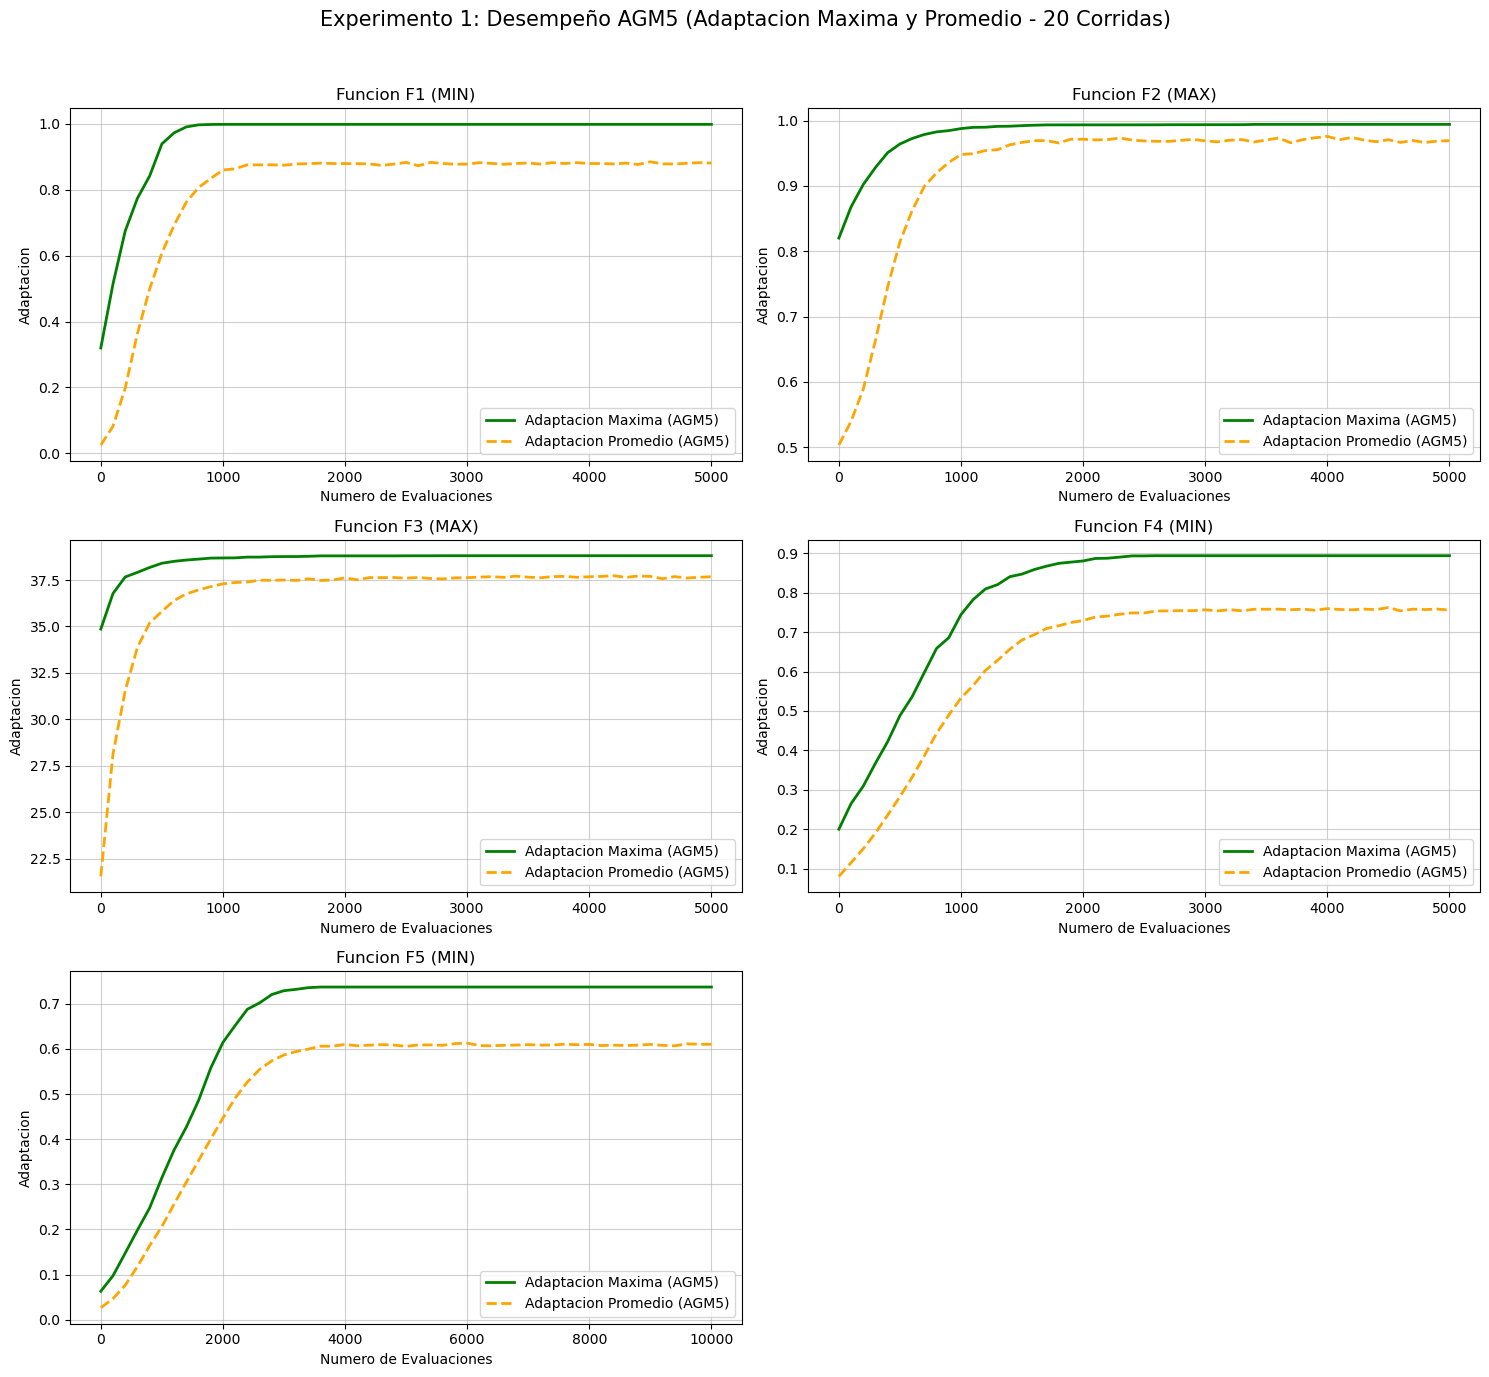

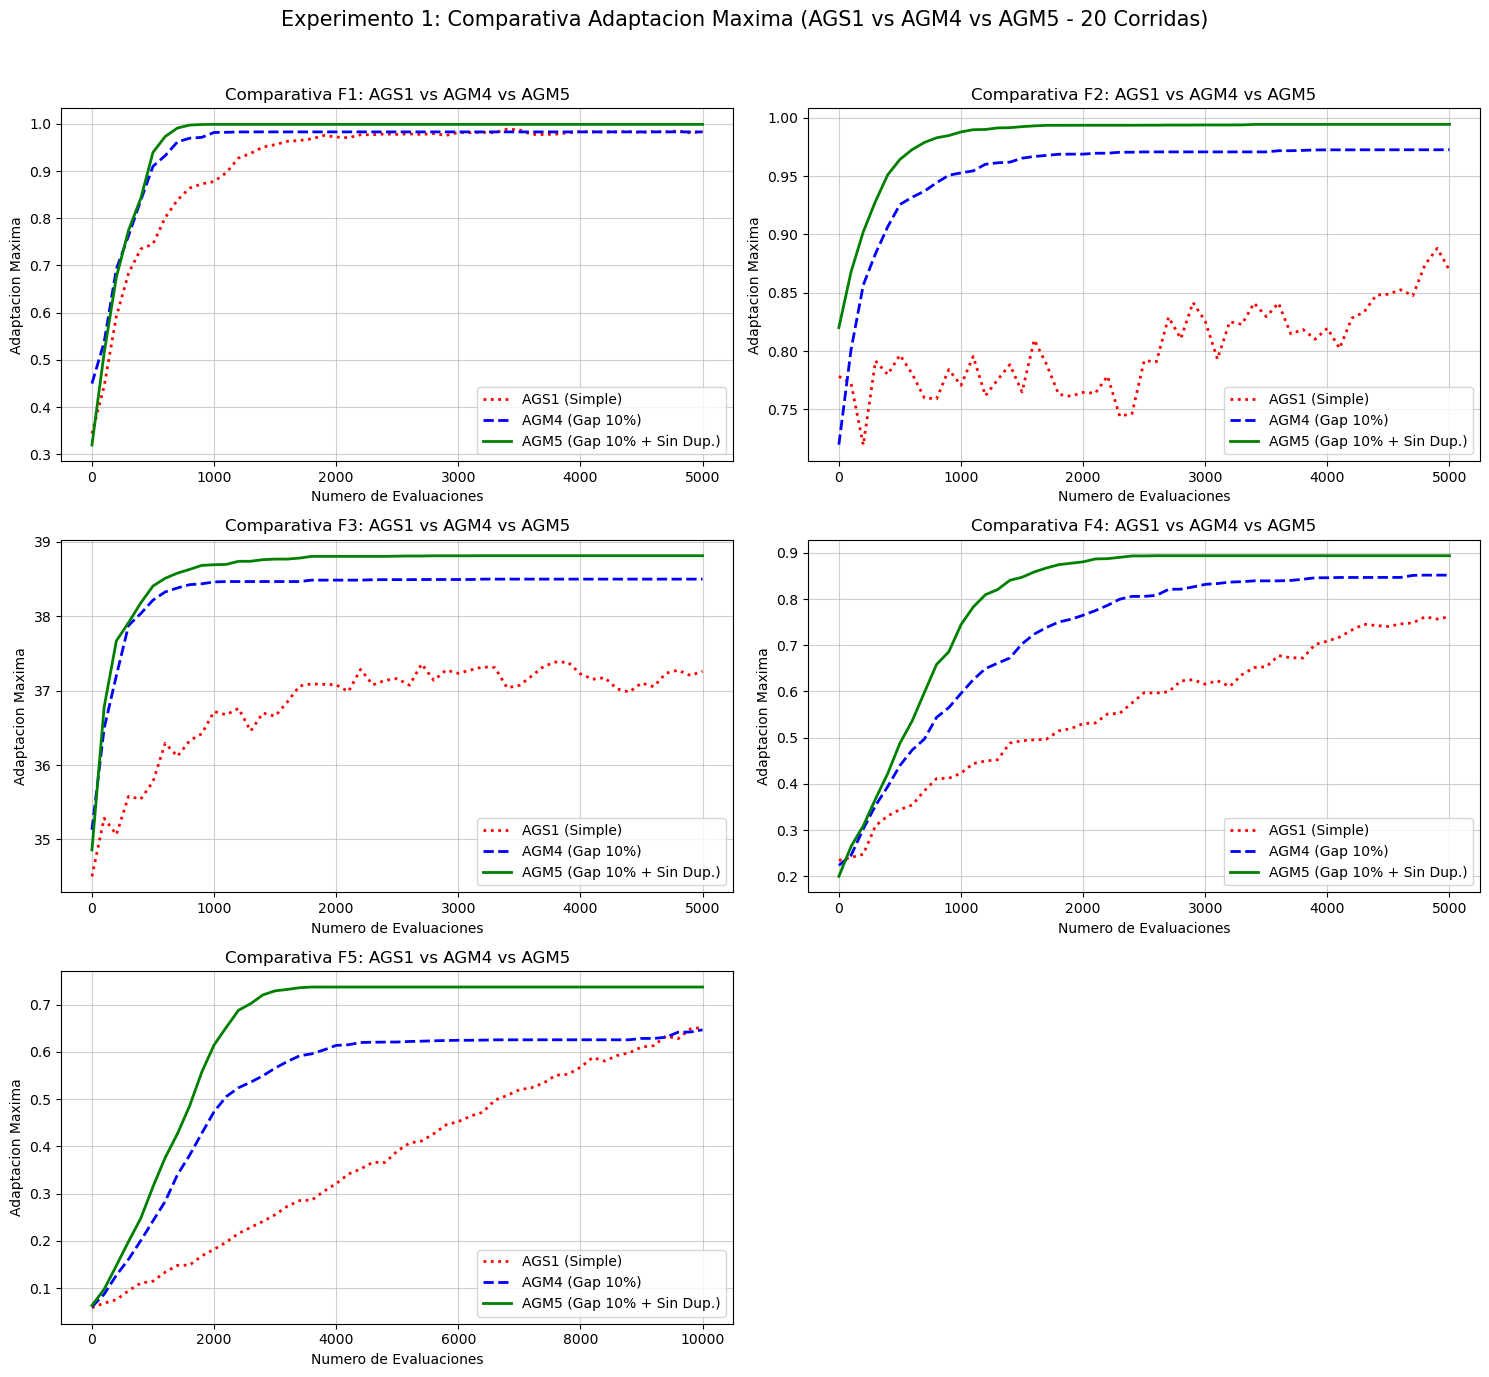


               TABLA 1 (EXP 1): MEJOR INDIVIDUO ENCONTRADO EN LAS 20 CORRIDAS (AGS1 vs AGM5)              
Func  | Algoritmo | Adaptacion   | Valor f(x,y,[z]) | Decodificacion (Variables x, y, [z])
----------------------------------------------------------------------------------------------------------
F1    | AGS1      | 0.998858     | 0.001143         | [0.00489, 0.00489]
F1    | AGM4      | 0.998858     | 0.001143         | [-0.00489, 0.00489]
F1    | AGM5      | 0.998858     | 0.001143         | [0.00489, 0.00489]
----------------------------------------------------------------------------------------------------------
F2    | AGS1      | 0.990275     | 0.990275         | [1.89520, 2.50557]
F2    | AGM4      | 0.999981     | 0.999981         | [0.00305, -0.00305]
F2    | AGM5      | 0.999981     | 0.999981         | [-0.00305, 0.00305]
----------------------------------------------------------------------------------------------------------
F3    | AGS1      | 38.815499    | 38.8

In [12]:
print("\n=====================================================================================")
print("                 EXPERIMENTO 1: OPTIMIZACION CON PARAMETROS FIJOS                    ")
print("     Comparacion AGM5 vs AGS1 y AGM4 (Promedio sobre 20 corridas por funcion)        ")
print("=====================================================================================\n")

N_CORRIDAS = 20
N_POB = 100
PRECISION_DEC = 2  # Garantiza al menos 10^-2

# Reporte de parametros y bits asignados por variable
print("REPORTE DE PARAMETROS Y PRECISION DE VARIABLES:")
print(f"- Tamano de Poblacion (N): {N_POB} | Corridas por funcion: {N_CORRIDAS} | Precision: 10^-{PRECISION_DEC}")
print(f"- Parametros AGM5: Pc = 0.90, Pm = 0.01, Gap = 10%, Tope = 100, Paso = 1")
print(f"- Parametros AGS1: Pc = 0.90, Pm = 0.01, Reemplazo = 100%\n")

for nf in ["F1", "F2", "F3", "F4", "F5"]:
    bits_v = calcular_estructura_bits(nf, PRECISION_DEC)
    print(f"  * {nf} ({CATALOGO_FUNCIONES[nf]['tipo']}): Bits por variable = {bits_v} (Total cromosoma = {sum(bits_v)} bits)")

resultados_exp1 = {}

# Figura 1: Adaptacion Maxima y Promedio del AGM5 para las 5 funciones
fig1, axs1 = plt.subplots(3, 2, figsize=(15, 14))
fig1.suptitle("Experimento 1: Desempeño AGM5 (Adaptacion Maxima y Promedio - 20 Corridas)", fontsize=15)

# Figura 2: Comparativa Adaptacion Maxima AGS1 vs AGM4 vs AGM5 para las 5 funciones
fig2, axs2 = plt.subplots(3, 2, figsize=(15, 14))
fig2.suptitle("Experimento 1: Comparativa Adaptacion Maxima (AGS1 vs AGM4 vs AGM5 - 20 Corridas)", fontsize=15)

funciones_lista = ["F1", "F2", "F3", "F4", "F5"]

for idx, nf in enumerate(funciones_lista):
    # Como sugiere el enunciado, para F5 aumentamos las evaluaciones para observar mejor convergencia
    evals_func = 10000 if nf == "F5" else 5000
    print(f"\nEjecutando 20 corridas para {nf} ({evals_func} evaluaciones por corrida)...")

    # Ejecucion AGS1, AGM4 y AGM5
    eje_x, max_ags1, prom_ags1, mejor_ags1 = ejecutar_multiples_corridas(
        "AGS1", nf, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=evals_func,
        precision=PRECISION_DEC, pc=0.9, pm=0.01
    )
    _, max_agm4, prom_agm4, mejor_agm4 = ejecutar_multiples_corridas(
        "AGM4", nf, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=evals_func,
        precision=PRECISION_DEC, pc=0.9, pm=0.01, gap=0.10, tope=100, paso=1
    )
    _, max_agm5, prom_agm5, mejor_agm5 = ejecutar_multiples_corridas(
        "AGM5", nf, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=evals_func,
        precision=PRECISION_DEC, pc=0.9, pm=0.01, gap=0.10, tope=100, paso=1
    )

    resultados_exp1[nf] = {
        "AGS1": mejor_ags1,
        "AGM4": mejor_agm4,
        "AGM5": mejor_agm5
    }

    fila, col = idx // 2, idx % 2

    # Grafica 1: AGM5 (Adaptacion Maxima y Promedio)
    ax1 = axs1[fila, col]
    ax1.plot(eje_x, max_agm5, label="Adaptacion Maxima (AGM5)", color="green", linewidth=2)
    ax1.plot(eje_x, prom_agm5, label="Adaptacion Promedio (AGM5)", color="orange", linestyle="--", linewidth=2)
    ax1.set_title(f"Funcion {nf} ({CATALOGO_FUNCIONES[nf]['tipo']})")
    ax1.set_xlabel("Numero de Evaluaciones")
    ax1.set_ylabel("Adaptacion")
    ax1.grid(True, alpha=0.6)
    ax1.legend(loc="lower right")

    # Grafica 2: Comparativa AGS1 vs AGM4 vs AGM5
    ax2 = axs2[fila, col]
    ax2.plot(eje_x, max_ags1, label="AGS1 (Simple)", color="red", linestyle=":", linewidth=2)
    ax2.plot(eje_x, max_agm4, label="AGM4 (Gap 10%)", color="blue", linestyle="--", linewidth=2)
    ax2.plot(eje_x, max_agm5, label="AGM5 (Gap 10% + Sin Dup.)", color="green", linewidth=2)
    ax2.set_title(f"Comparativa {nf}: AGS1 vs AGM4 vs AGM5")
    ax2.set_xlabel("Numero de Evaluaciones")
    ax2.set_ylabel("Adaptacion Maxima")
    ax2.grid(True, alpha=0.6)
    ax2.legend(loc="lower right")

# Ocultar el sexto subgrafico vacio
axs1[2, 1].axis("off")
axs2[2, 1].axis("off")

fig1.tight_layout(rect=[0, 0, 1, 0.96])
fig2.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Tabla Resumen Experimento 1
print("\n==========================================================================================================")
print("               TABLA 1 (EXP 1): MEJOR INDIVIDUO ENCONTRADO EN LAS 20 CORRIDAS (AGS1 vs AGM5)              ")
print("==========================================================================================================")
print(f"{'Func':<5} | {'Algoritmo':<9} | {'Adaptacion':<12} | {'Valor f(x,y,[z])':<16} | {'Decodificacion (Variables x, y, [z])'}")
print("-" * 106)

for nf in funciones_lista:
    for alg in ["AGS1", "AGM4", "AGM5"]:
        m = resultados_exp1[nf][alg]
        coords_txt = ", ".join([f"{v:.5f}" for v in m["coords"]])
        print(f"{nf:<5} | {alg:<9} | {m['adap']:<12.6f} | {m['val_f']:<16.6f} | [{coords_txt}]")
    print("-" * 106)

# 6. Experimento 2: Desempeño del Algoritmo al Introducir Mejoras (AGS1 a AGM5)


           EXPERIMENTO 2: DESEMPEÑO AL INTRODUCIR MEJORAS INCREMENTALES              
      Evaluacion de AGS1, AGM2, AGM3, AGM4 y AGM5 (Gaps: 1%, 5% y 10%)               

Funcion seleccionada para el analisis incremental: F2 (MAX)
Parametros sugeridos en la guia:
- AGS1, AGM2, AGM3: Pc = 0.80, Pm = 0.002
- AGM4 y AGM5:      Pc = 0.90, Pm = 0.010 (Evaluando Gap de 1%, 5% y 10%)

TABLA 2 (EXP 2): COMPARACION DE PORCENTAJES DE SUSTITUCION (GAP 1%, 5%, 10%)

Algoritmo  | Gap (%)   | Adapt. Max Promedio Final  | Mejor Valor f(x,y) Alcanzado | Coordenadas [x, y]
---------------------------------------------------------------------------------------------------------
AGM4       |    1%     | 0.990341                   | 0.999981                     | [-0.00305, 0.00305]
AGM4       |    5%     | 0.978380                   | 0.999981                     | [-0.00305, 0.00305]
AGM4       |   10%     | 0.987587                   | 0.999981                     | [-0.00305, -0.00305]
------------

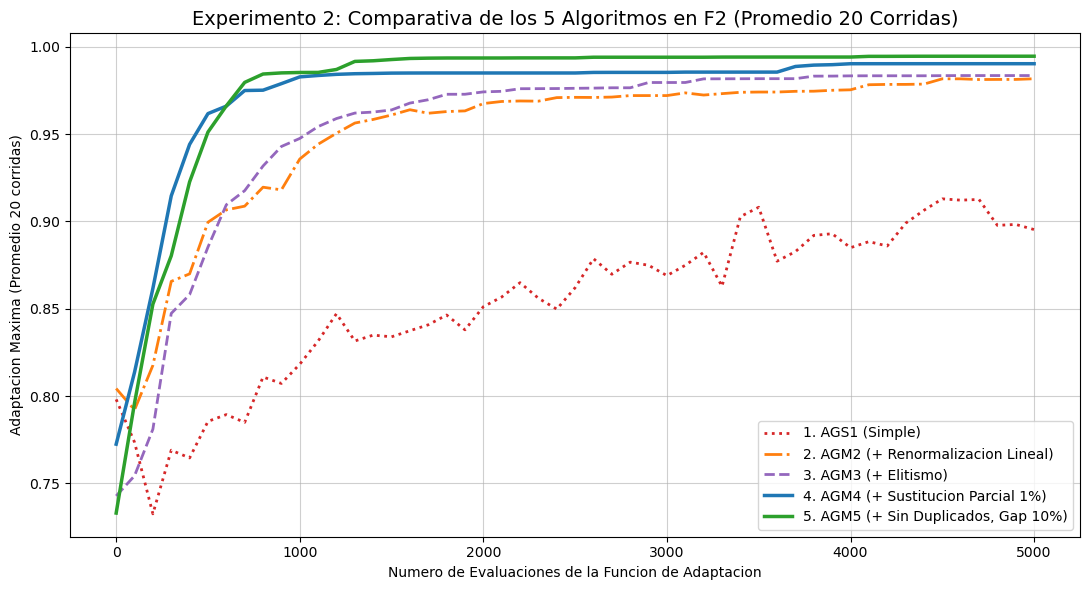

TABLA 3 (EXP 2): RESUMEN INCREMENTAL DE LOS 5 ALGORITMOS EN F2
Algoritmo              | Adapt. Max Final (20 corr.)  | Mejor f(x,y) Global  | Coordenadas [x, y]
----------------------------------------------------------------------------------------------------
AGS1 (Simple)          | 0.895340                     | 0.995513             | [-0.03357, -0.05799]
AGM2 (+Renorm)         | 0.981726                     | 0.999981             | [-0.00305, -0.00305]
AGM3 (+Elitismo)       | 0.983558                     | 0.999981             | [0.00305, -0.00305]
AGM4 (+Gap 1%)         | 0.990341                     | 0.999981             | [-0.00305, 0.00305]
AGM5 (+Sin Dup 10%)    | 0.994637                     | 0.999981             | [0.00305, 0.00305]
----------------------------------------------------------------------------------------------------


In [13]:
print("\n=====================================================================================")
print("           EXPERIMENTO 2: DESEMPEÑO AL INTRODUCIR MEJORAS INCREMENTALES              ")
print("      Evaluacion de AGS1, AGM2, AGM3, AGM4 y AGM5 (Gaps: 1%, 5% y 10%)               ")
print("=====================================================================================\n")

# Seleccionamos una funcion multimodal retadora del banco de pruebas (Ej. F2 o F4)
FUNCION_EXP2 = "F2"
EVALS_EXP2 = 5000

print(f"Funcion seleccionada para el analisis incremental: {FUNCION_EXP2} ({CATALOGO_FUNCIONES[FUNCION_EXP2]['tipo']})")
print("Parametros sugeridos en la guia:")
print("- AGS1, AGM2, AGM3: Pc = 0.80, Pm = 0.002")
print("- AGM4 y AGM5:      Pc = 0.90, Pm = 0.010 (Evaluando Gap de 1%, 5% y 10%)\n")

# 1. Ejecutar AGS1, AGM2, AGM3 (Con Pc=0.8 y Pm=0.002 segun guia)
eje_x, max_ags1, _, mejor_ags1 = ejecutar_multiples_corridas(
    "AGS1", FUNCION_EXP2, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=EVALS_EXP2, pc=0.8, pm=0.002
)
_, max_agm2, _, mejor_agm2 = ejecutar_multiples_corridas(
    "AGM2", FUNCION_EXP2, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=EVALS_EXP2, pc=0.8, pm=0.002, tope=100, paso=1
)
_, max_agm3, _, mejor_agm3 = ejecutar_multiples_corridas(
    "AGM3", FUNCION_EXP2, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=EVALS_EXP2, pc=0.8, pm=0.002, tope=100, paso=1
)

# 2. Evaluar AGM4 y AGM5 variando el porcentaje de sustitucion (1%, 5% y 10%) con Pc=0.9 y Pm=0.01
gaps_a_probar = [0.01, 0.05, 0.10]
resultados_gaps = {"AGM4": {}, "AGM5": {}}

for g in gaps_a_probar:
    _, c_max4, _, m4 = ejecutar_multiples_corridas(
        "AGM4", FUNCION_EXP2, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=EVALS_EXP2, pc=0.9, pm=0.01, gap=g, tope=100, paso=1
    )
    _, c_max5, _, m5 = ejecutar_multiples_corridas(
        "AGM5", FUNCION_EXP2, n_corridas=N_CORRIDAS, n_pob=N_POB, max_evals=EVALS_EXP2, pc=0.9, pm=0.01, gap=g, tope=100, paso=1
    )
    resultados_gaps["AGM4"][g] = {"curva_max": c_max4, "mejor": m4, "final_prom": c_max4[-1]}
    resultados_gaps["AGM5"][g] = {"curva_max": c_max5, "mejor": m5, "final_prom": c_max5[-1]}

# Tabla Comparativa de Porcentajes de Sustitucion (1%, 5% y 10%)
print("TABLA 2 (EXP 2): COMPARACION DE PORCENTAJES DE SUSTITUCION (GAP 1%, 5%, 10%)\n")
print(f"{'Algoritmo':<10} | {'Gap (%)':<9} | {'Adapt. Max Promedio Final':<26} | {'Mejor Valor f(x,y) Alcanzado':<28} | {'Coordenadas [x, y]'}")
print("-" * 105)

mejor_gap_agm4 = max(gaps_a_probar, key=lambda g: resultados_gaps["AGM4"][g]["final_prom"])
mejor_gap_agm5 = max(gaps_a_probar, key=lambda g: resultados_gaps["AGM5"][g]["final_prom"])

for alg in ["AGM4", "AGM5"]:
    for g in gaps_a_probar:
        datos_g = resultados_gaps[alg][g]
        m = datos_g["mejor"]
        coords_str = ", ".join([f"{v:.5f}" for v in m["coords"]])
        print(f"{alg:<10} | {int(g*100):>4}%     | {datos_g['final_prom']:<26.6f} | {m['val_f']:<28.6f} | [{coords_str}]")
    print("-" * 105)

print(f"-> Mejor porcentaje de sustitucion encontrado: AGM4 = {int(mejor_gap_agm4*100)}% | AGM5 = {int(mejor_gap_agm5*100)}%\n")


# 3. Grafica Unica Comparativa de los 5 Algoritmos (con el mejor porcentaje de sustitucion encontrado)
plt.figure(figsize=(11, 6))
plt.title(f"Experimento 2: Comparativa de los 5 Algoritmos en {FUNCION_EXP2} (Promedio 20 Corridas)", fontsize=14)

plt.plot(eje_x, max_ags1, label="1. AGS1 (Simple)", color="#d62728", linestyle=":", linewidth=2)
plt.plot(eje_x, max_agm2, label="2. AGM2 (+ Renormalizacion Lineal)", color="#ff7f0e", linestyle="-.", linewidth=2)
plt.plot(eje_x, max_agm3, label="3. AGM3 (+ Elitismo)", color="#9467bd", linestyle="--", linewidth=2)
plt.plot(
    eje_x, resultados_gaps["AGM4"][mejor_gap_agm4]["curva_max"],
    label=f"4. AGM4 (+ Sustitucion Parcial {int(mejor_gap_agm4*100)}%)", color="#1f77b4", linewidth=2.5
)
plt.plot(
    eje_x, resultados_gaps["AGM5"][mejor_gap_agm5]["curva_max"],
    label=f"5. AGM5 (+ Sin Duplicados, Gap {int(mejor_gap_agm5*100)}%)", color="#2ca02c", linewidth=2.5
)

plt.xlabel("Numero de Evaluaciones de la Funcion de Adaptacion")
plt.ylabel("Adaptacion Maxima (Promedio 20 corridas)")
plt.grid(True, alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# Tabla Resumen Final de los 5 Algoritmos
print("TABLA 3 (EXP 2): RESUMEN INCREMENTAL DE LOS 5 ALGORITMOS EN", FUNCION_EXP2)
print(f"{'Algoritmo':<22} | {'Adapt. Max Final (20 corr.)':<28} | {'Mejor f(x,y) Global':<20} | {'Coordenadas [x, y]'}")
print("-" * 100)

resumen_5_algs = [
    ("AGS1 (Simple)", max_ags1[-1], mejor_ags1),
    ("AGM2 (+Renorm)", max_agm2[-1], mejor_agm2),
    ("AGM3 (+Elitismo)", max_agm3[-1], mejor_agm3),
    (f"AGM4 (+Gap {int(mejor_gap_agm4*100)}%)", resultados_gaps["AGM4"][mejor_gap_agm4]["final_prom"], resultados_gaps["AGM4"][mejor_gap_agm4]["mejor"]),
    (f"AGM5 (+Sin Dup {int(mejor_gap_agm5*100)}%)", resultados_gaps["AGM5"][mejor_gap_agm5]["final_prom"], resultados_gaps["AGM5"][mejor_gap_agm5]["mejor"]),
]

for nombre_a, prom_final, m_ind in resumen_5_algs:
    coords_str = ", ".join([f"{v:.5f}" for v in m_ind["coords"]])
    print(f"{nombre_a:<22} | {prom_final:<28.6f} | {m_ind['val_f']:<20.6f} | [{coords_str}]")
print("-" * 100)

Puntos Clave para la Discusión en tu Reporte
Impacto de la Renormalización Lineal (AGS1 
→
→
 AGM2):
En AGS1, cuando aparece un "superindividuo" al principio de la evolución o cuando toda la población tiene valores de adaptación muy parecidos al final (ej. en 
F
2
F 
2
​
 
 donde muchos individuos rondan 
0.99
0.99
), la ruleta tradicional sufre de convergencia prematura o de estancamiento por falta de presión selectiva.
AGM2 corrige esto al asignar aptitudes basadas en el orden (ranking) mediante 
Tope
−
i
⋅
Paso
Tope−i⋅Paso
, manteniendo una presión selectiva constante desde la evaluación 
0
0
 hasta la 
5000
5000
.
Impacto del Elitismo (AGM2 
→
→
 AGM3):
En AGS1 y AGM2, las curvas de adaptación máxima suben y bajan debido a que el cruce y la mutación pueden destruir al mejor individuo de la generación. Con AGM3, la curva de adaptación máxima se vuelve monótonamente creciente (nunca retrocede).
Impacto de la Sustitución Parcial (AGM3 
→
→
 AGM4 con Gaps de 1%, 5% y 10%):
Al sustituir solo el 
1
%
1%
, 
5
%
5%
 o 
10
%
10%
 peor de la población en cada paso, los nuevos hijos de alta calidad entran inmediatamente al grupo reproductor en la siguiente micro-generación sin esperar a que se evalúen 
100
100
 individuos. Esto produce una pendiente de aprendizaje mucho más rápida en las primeras 
1000
1000
 evaluaciones.
Impacto de Eliminar Duplicados (AGM4 
→
→
 AGM5):
En algoritmos con elitismo y gap generacional pequeño, la población tiende a llenarse rápidamente de clones del mejor individuo. AGM5 impide evaluar clones, obligando a que cada una de las 
5000
5000
 evaluaciones explore un punto distinto del espacio de búsqueda, logrando escapar de óptimos locales en funciones altamente multimodales como 
F
2
,
F
4
F 
2
​
 ,F 
4
​
 
 y 
F
5
F 
5
​
 
.